Karen Mayerli Tahuite Ortiz  
carnet: 202103058    
  
Burden (10e)  
Ejercicios 5.2 
Preguntas de análisis  
Versión de python 3.12.0

3. Use el método de Euler para aproximar una solución para el problema de valor inicial $\frac{dy}{dt}=e^t\cos(t)$ para $t$ entre $0$ y $5$. Inicie con un tamaño de paso de $0.25$, a continuación pruebe el tamaño de paso de $0.1$ o incluso $0.05$ o menor. Utilice una hoja de cálculo o un sistema de álgebra para computadora para los cálculos.  
  
¿La solución es la que esperaba? ¿Qué está pasando y por qué?

Dado que el enunciado del ejercicio omite la condición inicial necesaria para plantear el problema de Valor Inicial (PVI), y como la derivada $y' = e^t \cos(t)$ no contiene a la variable $y$, cualquier cambio en el valor inicial solo provocará una traslación vertical de la curva sin alterar el comportamiento global del error numérico. Por lo tanto, sin pérdida de generalidad, se va a considerar que $y(0) = 0$.


In [46]:
# Librerias 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from IPython.display import display, Math

In [47]:
# Parámetros del P.V.I.
a = 0
b = 5
alpha = 0

# Tamaños de paso
h1 = 0.25
h2 = 0.1
h3 = 0.05
h4 = 0.005

# Función f(t,y)
def f(t, y):
    return np.exp(t) * np.cos(t)

# Solución exacta
def y_exacta(t):
    return (1/ 2) * (np.exp(t) * np.sin(t) + np.exp(t) * np.cos(t) - 1)

In [48]:
# Implementación del método de Euler

def euler(f, a, b, alpha, h):
    
    # Número de pasos
    N = int((b - a) / h)

    # Vectores
    t = np.zeros(N + 1)
    w = np.zeros(N + 1)

    # Condiciones iniciales
    t[0] = a
    w[0] = alpha

    # Método de Euler
    for i in range(N):
        t[i + 1] = t[i] + h
        w[i + 1] = w[i] + h * f(t[i], w[i])

    return t, w

In [49]:
# Aproximaciones con los cuatro tamaños de paso

t1, w1 = euler(f, a, b, alpha, h1)
t2, w2 = euler(f, a, b, alpha, h2)
t3, w3 = euler(f, a, b, alpha, h3)
t4, w4 = euler(f, a, b, alpha, h4)

In [50]:
# Como las mallas que generan h_2, h_3 y h_4 poseen muchos nodos, para las aproximaciones obtenidas con los 4 tamaños de paso
# solo se considerarán algunas aproximaciones para ser mostradas.
# t = {0, 1, 2, 3, 4, 5}

# Valores de t que se mostrarán
puntos = [0, 1, 2, 3, 4, 5]

# Tabla de aproximaciones
tabla_aproximaciones = pd.DataFrame({
    "t": puntos,
    "h1 = 0.25": [w1[int(t / h1)] for t in puntos],
    "h2 = 0.1": [w2[int(t / h2)] for t in puntos],
    "h3 = 0.05": [w3[int(t / h3)] for t in puntos],
    "h4 = 0.005": [w4[int(t / h4)] for t in puntos]
})

tabla_aproximaciones


,t,h1 = 0.25,h2 = 0.1,h3 = 0.05,h4 = 0.005
0,0,0.000000,0.000000,0.000000,0.000000
1,1,1.309996,1.353075,1.365928,1.376849
2,2,1.775137,1.516711,1.421583,1.332124
3,3,-6.538195,-8.000574,-8.507858,-8.972868
4,4,-34.394628,-37.165649,-38.085717,-38.912145
5,5,-54.792102,-52.511031,-51.598160,-50.711256


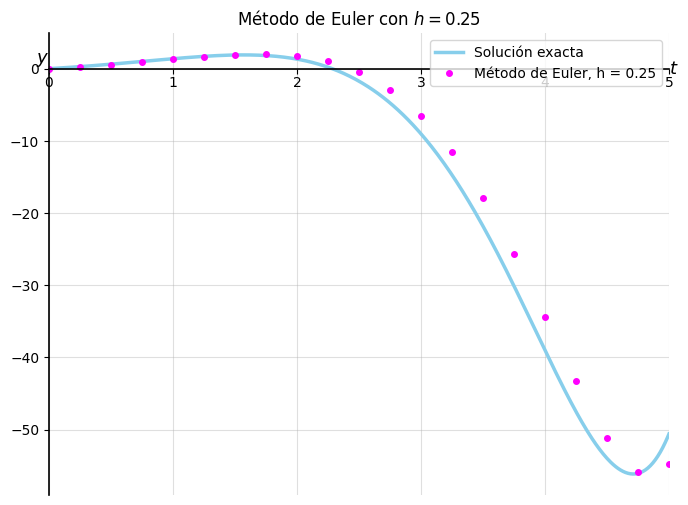

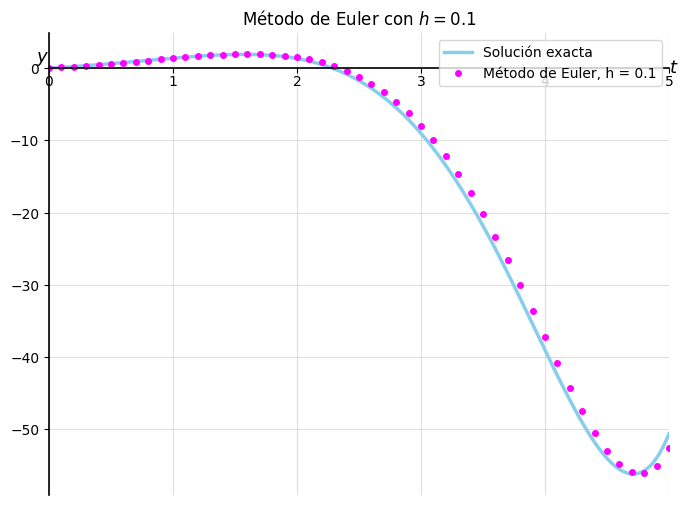

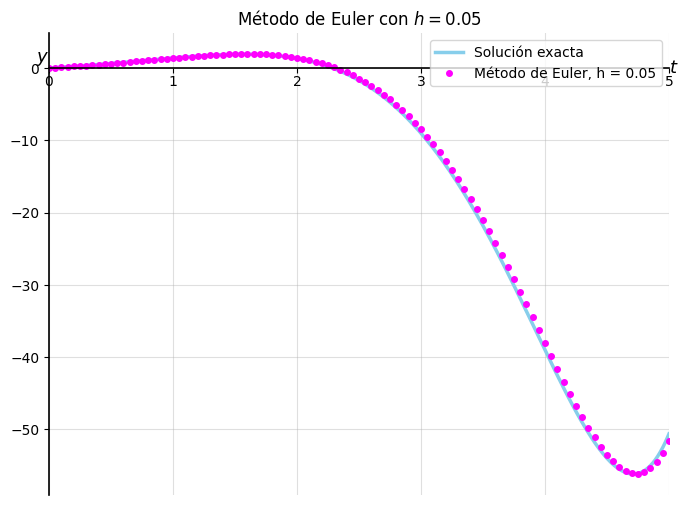

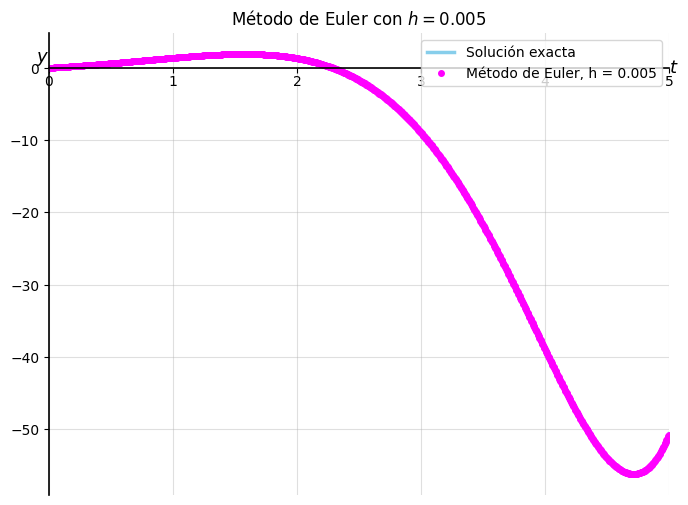

In [ ]:
# Gráficas comparativas del método de Euler para cada tamaño de paso
# Para las gráficas si se tomará en cuenta toda la malla.

# Función exacta
t_exacta = np.linspace(0, 5, 500)
y_exacta_grafica = y_exacta(t_exacta)

# Datos de cada tamaño de paso
datos = [
    (t1, w1, h1),
    (t2, w2, h2),
    (t3, w3, h3),
    (t4, w4, h4)
]

for t, w, h in datos:

    fig, ax = plt.subplots(figsize=(8, 6))

    # Solución exacta
    ax.plot(
        t_exacta,
        y_exacta_grafica,
        color="#87CEEB",
        linewidth=2.5,
        label=r"Solución exacta"
    )

    # Puntos del método de Euler
    ax.plot(
        t,
        w,
        "o",
        color="magenta",
        markersize=4,
        label=f"Método de Euler, h = {h}"
    )

    # Límites
    ax.set_xlim(0, 5)

    # Ajuste automático del eje vertical
    ymin = min(np.min(w), np.min(y_exacta_grafica))
    ymax = max(np.max(w), np.max(y_exacta_grafica))
    margen = 0.05 * (ymax - ymin)

    ax.set_ylim(ymin - margen, ymax + margen)

    # Eje horizontal
    ax.spines["top"].set_position(("data", 0))
    ax.spines["top"].set_linewidth(1.2)

    # Eje vertical
    ax.spines["left"].set_position(("data", 0))
    ax.spines["left"].set_linewidth(1.2)

    ax.spines["bottom"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Marcas del eje t
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.xaxis.set_ticks_position("top")
    ax.tick_params(
        axis="x",
        labeltop=True,
        labelbottom=False,
        direction="in",
        pad=-15
    )

    # Etiquetas de los ejes
    ax.text(5, 0, "$t$", fontsize=13, ha="left", va="center")
    ax.text(0, 0, "$y$", fontsize=13, ha="right", va="bottom")

    # Cuadrícula
    ax.grid(True, alpha=0.4)

    # Título
    ax.set_title(f"Método de Euler con $h={h}$")

    ax.legend()

    plt.show()

### Análisis de los resultados

Respondiendo a las preguntas planteadas, las soluciones obtenidas son las esperadas, ya que presentan errores relativamente pequeños. Esto se puede observar visualmente, pues las aproximaciones mediante el método de Euler siguen de manera cercana a la solución exacta.

**Teóricamente**, al utilizar un tamaño de paso aún menor, se obtendría una aproximación con un error menor. Sin embargo, disminuir demasiado el tamaño de paso incrementa considerablemente el número de cálculos necesarios, lo cual computacional no es óptimo ya que los errores de redondeo se iran acumulando provacando aproxiamciones con más erorr.

Al comparar los cuatro tamaños de paso utilizados, se observa que para $h_1=0.25$ existe un error relativo más evidente en comparación con los demás tamaños de paso a partir de $t=2$ debido a que es el paso más grande. Esto se debe al cambio brusco de comportamiento de la solución la cual comienza a descender bruscamente en el intervalo $[\frac{\pi}{2},\frac{3\pi}{2}]\approx [1.570796,4.71238898]$.
